In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
import pyogrio
import glob
import seaborn as sns
import matplotlib.lines as mlines
from math import radians, cos, sin, asin, sqrt
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [ ]:
caminho_gpkg = "./data/ibge_census_data_2022/niteroi_census_borders.gpkg"
print(pyogrio.list_layers(caminho_gpkg))

[['favelas_e_comunidades_censo2022' 'MultiPolygon']
 ['setores_censitarios_2022_ssagi' 'Polygon']]


In [3]:
mapa_niteroi = gpd.read_file(caminho_gpkg, layer='setores_censitarios_2022_ssagi')
mapa_favelas = gpd.read_file(caminho_gpkg, layer='favelas_e_comunidades_censo2022')

In [ ]:
# Inicializando tabela geral
arquivos = glob.glob("./data/mobility_data/*.csv")
tabela = [pd.read_csv(arquivo) for arquivo in arquivos]
tabela = pd.concat(tabela, ignore_index=True)
tabela["timestamp"] = pd.to_datetime(tabela["timestamp"])
tabela["hora"] = pd.to_datetime(tabela["timestamp"]).dt.hour
tabela["dia"] = pd.to_datetime(tabela["timestamp"]).dt.day

In [ ]:
# Inicializando tabela de chuva
chuva = pd.read_csv("./data/auxiliar_data/meteorological_data.csv")
chuva = chuva[["Timestamp (UTC)", "Wind Speed (m/s)", "Rain (mm)"]]
chuva["Timestamp (UTC)"] = pd.to_datetime(chuva["Timestamp (UTC)"])
chuva["hora"] = pd.to_datetime(chuva["Timestamp (UTC)"]).dt.hour
chuva["dia"] = pd.to_datetime(chuva["Timestamp (UTC)"]).dt.day
chuva = chuva.fillna(method="ffill")

In [ ]:
# Fazendo o merge das tabelas
tabela = tabela.reset_index()

tabela = tabela.merge(
    chuva[['dia', 'hora', 'Rain (mm)']], 
    on=['dia', 'hora'], 
    how='left'
)

In [7]:
#função que calcula a distancia entre dois pontos na superficie da terra
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(radians, [lon1, lat1, lon2, lat2])
    dlon, dlat = lon2 - lon1, lat2 - lat1 
    a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2
    return 2 * asin(sqrt(a)) * 6371

tabela = tabela.sort_values(['tripId', 'timestamp'])

trip_stats = tabela.groupby(['tripId', 'dia', 'id', 'direction']).agg(
    lineId=('lineId', 'first'),
    lineName=('lineName', 'unique'),
    min_time=('timestamp', 'min'),
    max_time=('timestamp', 'max'),
    start_lat=('lat', 'first'),
    start_lng=('lng', 'first'),
    end_lat=('lat', 'last'),
    end_lng=('lng', 'last'),
    rain=("Rain (mm)", "max")
).reset_index()

trip_stats['duration_min'] = (trip_stats['max_time'] - trip_stats['min_time']).dt.total_seconds() / 60.0
trip_stats['dist_km'] = trip_stats.apply(lambda x: haversine(x.start_lng, x.start_lat, x.end_lng, x.end_lat), axis=1)

trip_stats = trip_stats[(trip_stats['duration_min'] > 5) & (trip_stats['dist_km'] > 0.5)]

trip_stats = trip_stats[trip_stats["duration_min"] < 300]

trip_stats['avg_velocity'] = trip_stats['dist_km']/(trip_stats['duration_min'] / 60)

trip_stats = trip_stats[(trip_stats['avg_velocity'] >= 2) & (trip_stats['avg_velocity'] <= 80)]
trip_stats["atraso"] = trip_stats["duration_min"] - trip_stats.groupby(['lineId', 'direction'])['duration_min'].transform('median')

In [ ]:
# Leitura da planilha de paradas
stops = ["./data/GTFS_data/TransNit_20260320/stops.txt", "./data/GTFS_data/TransOceanico_20260315/stops.txt", "./data/GTFS_data/TransOceanico_20260329/stops.txt"]
stops = [pd.read_csv(stop) for stop in stops]
stops = pd.concat(stops, ignore_index=True)
stops

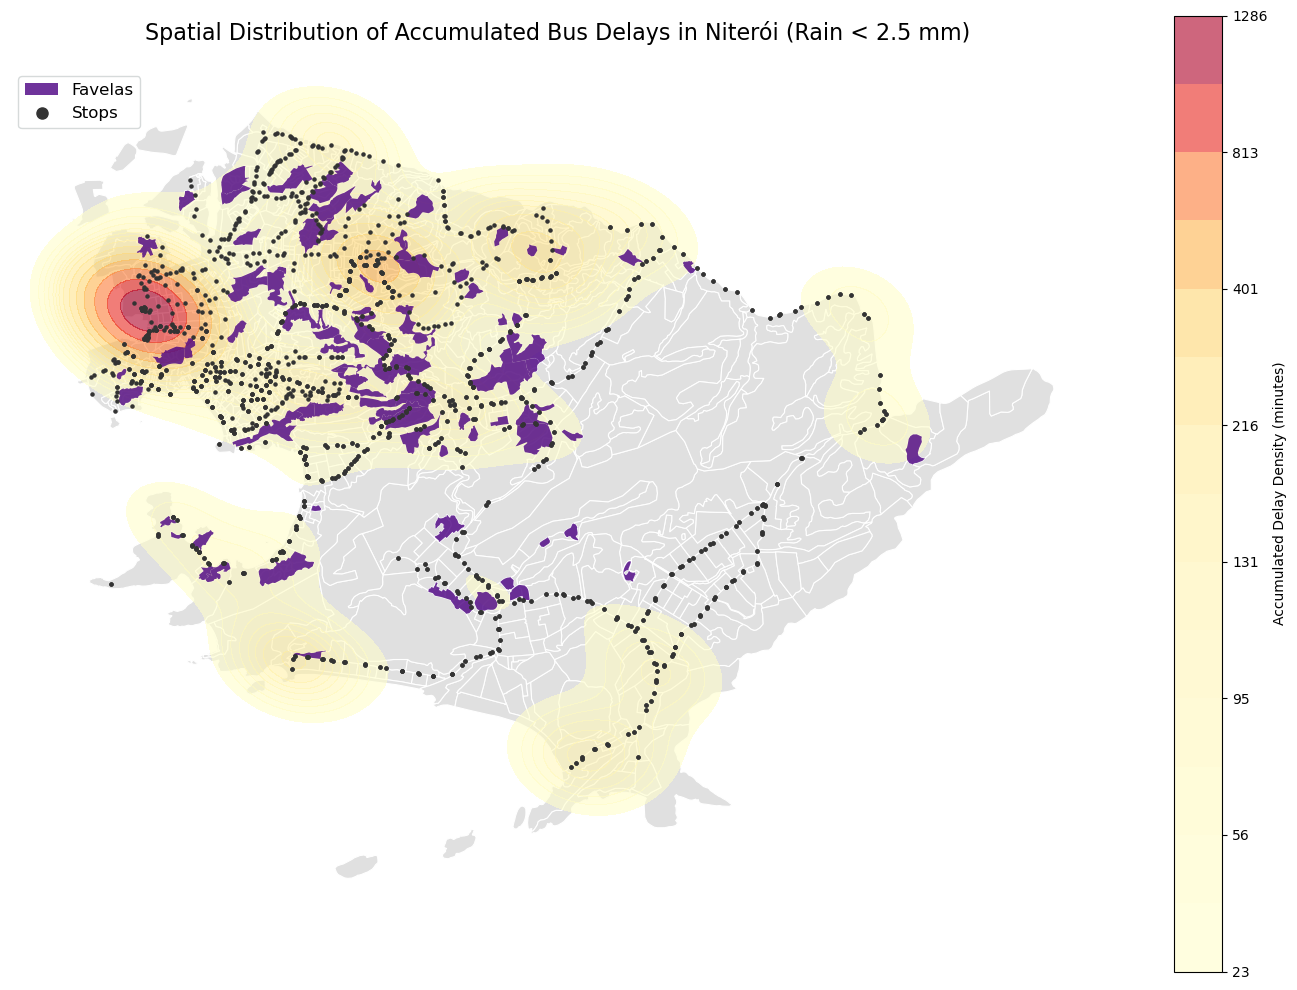

In [ ]:
# garantindo que a filtragem foi feita corretamente
no_rain = trip_stats[trip_stats["rain"] < 2.5].copy()

fig, ax = plt.subplots(figsize=(14, 10))

# 1. Mapa Base de Niterói
mapa_niteroi.plot(
    color="#e0e0e0",
    edgecolor="#ffffff",
    linewidth=0.8,
    ax=ax,
)

# alterando de 'trip_stats' para 'no_rain' em todos os campos do KDE
sns.kdeplot(
    x=no_rain['start_lng'],
    y=no_rain['start_lat'],
    weights=no_rain["atraso"].clip(lower=0),
    cmap="YlOrRd",
    fill=True,
    alpha=0.6,
    thresh=0.08,
    levels=15,
    cbar=True,
    cbar_kws={"label": "Accumulated Delay Density (minutes)"},
    ax=ax  # Este ax garante que o Seaborn use o mesmo plano do GeoPandas
)

# Camada de Favelas
mapa_favelas.plot(
    ax=ax,
    color="indigo",
    linewidth=1.5,
    markersize=15,
    alpha=0.8,
)

legenda_favelas = mpatches.Patch(
    facecolor="indigo", 
    alpha=0.8, 
    label="Favelas"
)

# incluindo a legenda dos 'Stops'
legenda_stops = mlines.Line2D(
    [], [], 
    color='#333333', 
    marker='o', 
    linestyle='None', 
    markersize=8, 
    label='Stops'
)

ax.legend(
    handles=[legenda_favelas, legenda_stops],
    loc="upper left",
    fontsize=12, 
    frameon=True,
    facecolor="white",
    edgecolor="#ccd1d1"
)

# cria o GeoDataFrame assumindo que latitude/longitude original está em graus
gdf_pontos = gpd.GeoDataFrame(
    stops, 
    geometry=gpd.points_from_xy(stops['stop_lon'], stops['stop_lat']),
    crs=mapa_niteroi.crs
)

gdf_pontos = gpd.sjoin(gdf_pontos, mapa_niteroi, how="inner", predicate="intersects")

# Plot dos pontos
gdf_pontos.plot(ax=ax, color='#333333', marker='o', markersize=5)

plt.title("Spatial Distribution of Accumulated Bus Delays in Niterói (Rain < 2.5 mm)", fontsize=16, pad=20)

plt.axis("off")
plt.tight_layout()

plt.savefig("mapa_norain.pdf")
plt.show()


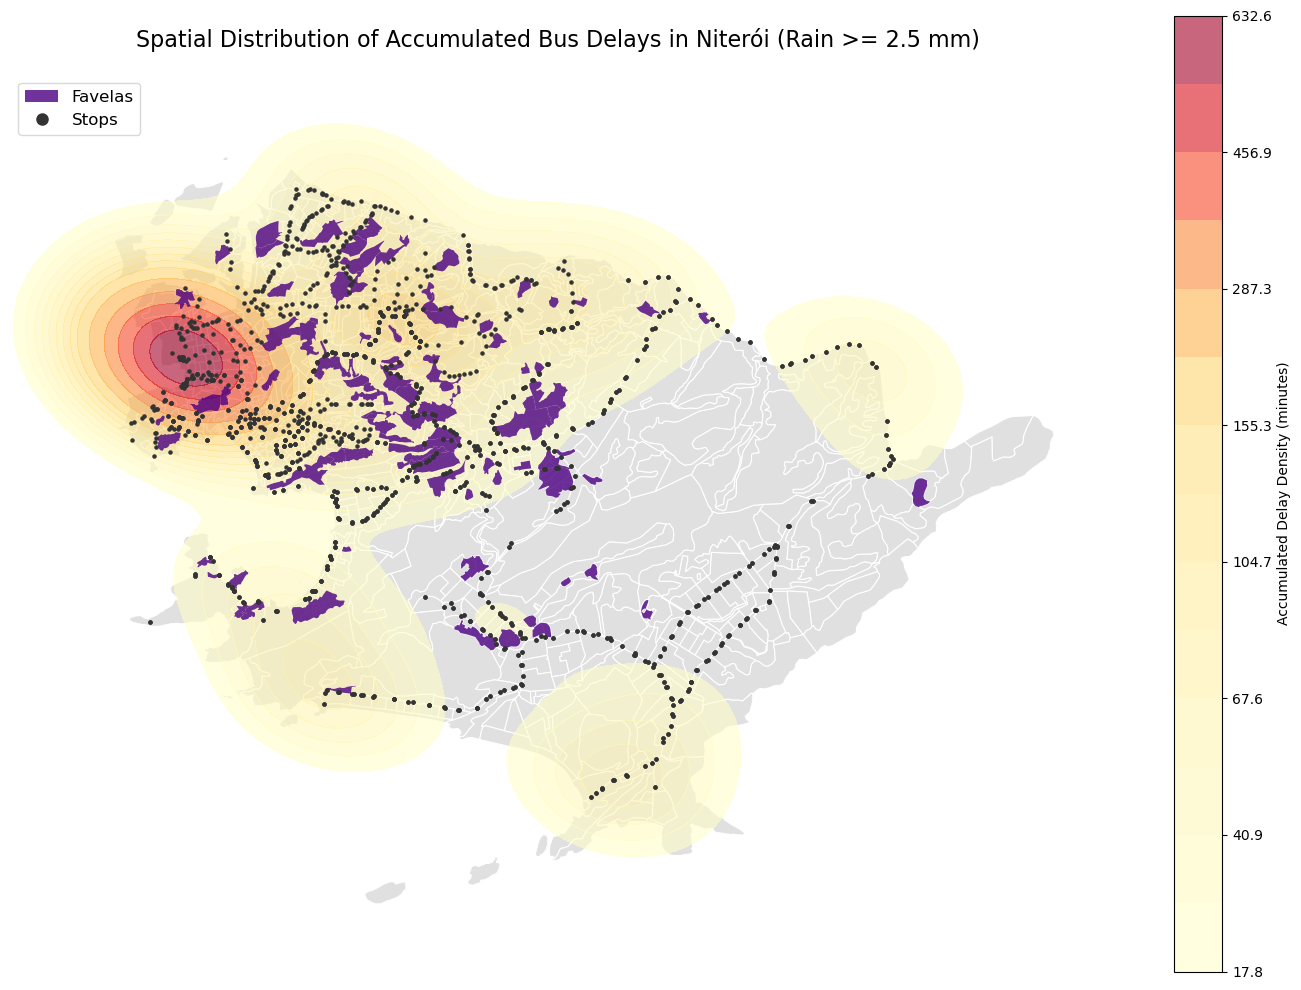

In [ ]:
# garantindo que a filtragem foi feita corretamente
rain = trip_stats[trip_stats["rain"] >= 2.5].copy()

fig, ax = plt.subplots(figsize=(14, 10))

# 1. Mapa Base de Niterói
mapa_niteroi.plot(
    color="#e0e0e0",
    edgecolor="#ffffff",
    linewidth=0.8,
    ax=ax,
)

# alterando de 'trip_stats' para 'no_rain' em todos os campos do KDE
sns.kdeplot(
    x=rain['start_lng'],
    y=rain['start_lat'],
    weights=rain["atraso"].clip(lower=0),
    cmap="YlOrRd",
    fill=True,
    alpha=0.6,
    thresh=0.08,
    levels=15,
    cbar=True,
    cbar_kws={"label": "Accumulated Delay Density (minutes)"},
    ax=ax  # Este ax garante que o Seaborn use o mesmo plano do GeoPandas
)

# Camada de Favelas
mapa_favelas.plot(
    ax=ax,
    color="indigo",
    linewidth=1.5,
    markersize=15,
    alpha=0.8,
)

legenda_favelas = mpatches.Patch(
    facecolor="indigo", 
    alpha=0.8, 
    label="Favelas"
)

# incluindo a legenda dos 'Stops'
legenda_stops = mlines.Line2D(
    [], [], 
    color='#333333', 
    marker='o', 
    linestyle='None', 
    markersize=8, 
    label='Stops'
)

ax.legend(
    handles=[legenda_favelas, legenda_stops],
    loc="upper left",
    fontsize=12, 
    frameon=True,
    facecolor="white",
    edgecolor="#ccd1d1"
)

# cria o GeoDataFrame assumindo que latitude/longitude original está em graus
gdf_pontos = gpd.GeoDataFrame(
    stops, 
    geometry=gpd.points_from_xy(stops['stop_lon'], stops['stop_lat']),
    crs=mapa_niteroi.crs
)

gdf_pontos = gpd.sjoin(gdf_pontos, mapa_niteroi, how="inner", predicate="intersects")

# plot dos pontos
gdf_pontos.plot(ax=ax, color='#333333', marker='o', markersize=5)

plt.title("Spatial Distribution of Accumulated Bus Delays in Niterói (Rain >= 2.5 mm)", fontsize=16, pad=20)

plt.axis("off")
plt.tight_layout()

plt.savefig("mapa_rain.pdf")
plt.show()